# FigS5f – ROI-based Fluorescence Intensity Analysis

## Overview
This notebook processes time-lapse fluorescence microscopy images and quantifies the average intensity within a user-defined Region of Interest (ROI).  
The ROI is defined by polygon annotations stored in JSON files. The script extracts raw intensities from two fluorescence channels and generates both numerical data and plots of intensity over time.

The analysis is designed for **full FRAP** experiments, where the entire ROI is bleached and no unbleached reference region is available.

---

## Input Requirements

1. **Two directories containing TIF images**
   - **Membrane channel** images  
   - **mbaojin channel** images  
   Filenames must include a timepoint identifier so that frames can be sorted and matched across channels.

2. **ROI annotation JSON files**
   - Generated from an image annotation tool (e.g. LabelMe)  
   - Each JSON contains polygon coordinates defining the ROI for a given frame  
   - The JSON filename should include the same timepoint identifier as the corresponding TIF image to allow matching

3. **Consistent frame indexing**
   - A `Frame` index is inferred from filenames and used to:
     - Match membrane and mbaojin images
     - Associate them with the correct ROI annotation
     - Define **pre-FRAP** and **post-FRAP** frames for normalization

---

## Processing Steps

For each matched membrane / mbaojin image pair and its ROI JSON:

1. **Load images and ROI**
   - Read the membrane-channel TIF
   - Read the mbaojin-channel TIF
   - Load the JSON file and rasterize the polygon into a binary mask

2. **Compute raw ROI intensities**
   - Apply the ROI mask to each channel
   - Compute the mean pixel value within the mask
   - Store as:
     - `Membrane_Raw_Intensity`
     - `mbaojin_Raw_Intensity`

3. **FRAP-style normalization (first frame = 1, second frame = 0)**  

   Since this is a full FRAP experiment with no separate reference region, we use a simple, frame-based normalization.

   Let the sorted unique frame indices be:

   $$
   f_1, f_2, f_3, \dots
   $$

   Interpret:

   - $f_1$: **pre-bleach** frame (before FRAP)
   - $f_2$: **first post-bleach** frame (after FRAP)

   For each channel, with raw intensity $I(t)$ at frame $t$, define:

   - $I_1 = I(f_1)$ (pre-bleach intensity)  
   - $I_2 = I(f_2)$ (first post-bleach intensity)

   The normalized FRAP curve is:

   $$
   F(t) = \frac{I(t) - I_2}{I_1 - I_2}
   $$

   This guarantees:

   - Pre-bleach frame:
     
     $$
     F(f_1) = 1
     $$

   - First post-bleach frame:
     
     $$
     F(f_2) = 0
     $$

   In the implementation:

   - The same transformation is applied independently to:
     - `Membrane_Raw_Intensity` → `Membrane_Normalized_Intensity`
     - `mbaojin_Raw_Intensity` → `mbaojin_Normalized_Intensity`
   - If $I_1 = I_2$ (degenerate case), the denominator is set to 1.0 to avoid division-by-zero.
   - Normalized values are clipped to the range $[0, 1]$ to suppress minor numerical overshoot due to noise.


---

## Outputs

The notebook produces:

1. **CSV file with per-frame intensity data**
   - Frame index and filenames  
   - `Membrane_Raw_Intensity`, `mbaojin_Raw_Intensity`  
   - `Membrane_Normalized_Intensity`, `mbaojin_Normalized_Intensity`  
     - Normalized according to  
       $$
       F(t) = \frac{I(t) - I_2}{I_1 - I_2}
       $$
       i.e.:
       - Pre-FRAP frame = 1.0  
       - First post-FRAP frame = 0.0  

2. **Plot(s) of normalized intensity vs. time**
   - FRAP recovery curves for both membrane and mbaojin channels  
   - Time axis in frames or in physical units (using `time_per_frame`)

3. **Summary statistics (optional)**
   - Basic statistics for raw and normalized intensities  
   - Final plateau values can be used as an approximate measure of recovery extent

---

## How to Run

1. **Set paths**
   - Update `membrane_dir`, `mbaojin_dir`, `output_svg_file`, and `output_csv_file` in the code cell to match your dataset.

2. **Configure analysis parameters**
   - Adjust `time_per_frame` and any other configuration variables as needed.

3. **Run all cells in order**
   - Execute the Jupyter Notebook from top to bottom.

4. **Inspect the outputs**
   - CSV file with raw and normalized intensity traces  
   - SVG (or other) plots showing normalized FRAP recovery curves for the selected ROI

=== File Mapping ===
t01: full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t01c2.tif + full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t01c1.tif -> full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t01c2.json (from c2_membrane)
t02: full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t02c2.tif + full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t02c1.tif -> full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t02c2.json (from c2_membrane)
t03: full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t03c2.tif + full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t03c1.tif -> full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t03c2.json (from c2_membrane)
t04: full-frap_250121-Create Image Subset and Split-11-Airyscan Processing-12_t04c2.tif + full-frap_250121-Create Image Subset and Split-11-Ai

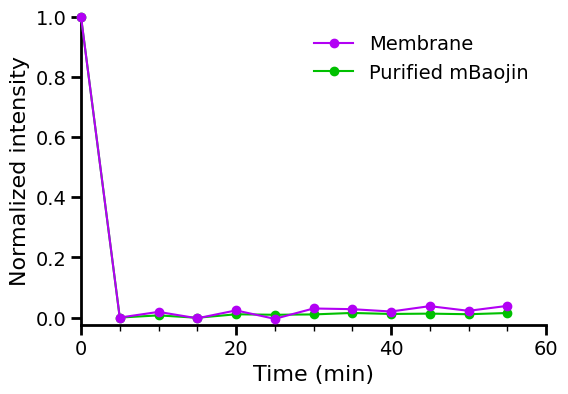

In [1]:
import sys
from pathlib import Path


try:
    from gear_data_analysis._bootstrap import bootstrap_notebook
except ModuleNotFoundError:
    def _find_repo_root(start: Path) -> Path:
        for candidate in (start, *start.parents):
            if (candidate / ".git").exists() or (
                (candidate / "pyproject.toml").exists()
                and (candidate / "src" / "gear_data_analysis" / "__init__.py").exists()
            ):
                return candidate
        raise FileNotFoundError("Repository root not found from current working directory.")

    REPO_ROOT = _find_repo_root(Path.cwd().resolve())
    SRC_ROOT = REPO_ROOT / "src"
    if str(SRC_ROOT) not in sys.path:
        sys.path.insert(0, str(SRC_ROOT))
    from gear_data_analysis._bootstrap import bootstrap_notebook

REPO_ROOT, SRC_ROOT = bootstrap_notebook(Path.cwd().resolve())

from gear_data_analysis.roi_timecourse_common import RoiTimecourseConfig, run_roi_timecourse

config = RoiTimecourseConfig(
    membrane_dir=Path("00_raw_FigS5f/c2_membrane"),
    secondary_dir=Path("00_raw_FigS5f/c1_mBaojin"),
    output_svg_file=Path("02_FigS5f_plot_output/FigS5f.svg"),
    output_csv_file=Path("02_FigS5f_plot_output/FigS5f.csv"),
    time_per_frame=5,
    secondary_column_key="mbaojin",
    secondary_plot_label="Purified mBaojin",
)

df_combined = run_roi_timecourse(config)
